# 3.1. Exploratory Data Analysis (EDA)
## Step 1: Data loading & initial inspection

In [1]:
import ast
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 80)

recipes = pd.read_csv("RAW_recipes.csv")
interactions = pd.read_csv("RAW_interactions.csv")

for name, df in [("RAW_recipes", recipes), ("RAW_interactions", interactions)]:
    print(f"=== {name} ===")
    print("Shape:", df.shape)
    print("Columns:", list(df.columns))
    display(df.head(3))

print("Unique recipes:", recipes["id"].nunique())
print("Unique users:", interactions["user_id"].nunique())
print("Recipes with >=1 interaction:", interactions["recipe_id"].nunique())

=== RAW_recipes ===
Shape: (231637, 12)
Columns: ['name', 'id', 'minutes', 'contributor_id', 'submitted', 'tags', 'nutrition', 'n_steps', 'steps', 'description', 'ingredients', 'n_ingredients']


,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
0,arriba baked winter squash mexican style,137739,55,47892,2005-09-16,"['60-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'cuisine...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'depending on size of squash , cut...",autumn is my favorite time of year to cook! this recipe \r\ncan be prepared ...,"['winter squash', 'mexican seasoning', 'mixed spice', 'honey', 'butter', 'ol...",7
1,a bit different breakfast pizza,31490,30,26278,2002-06-17,"['30-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'cuisine...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough into the bottom and sides of ...",this recipe calls for the crust to be prebaked a bit before adding ingredien...,"['prepared pizza crust', 'sausage patty', 'eggs', 'milk', 'salt and pepper',...",6
2,all in the kitchen chili,112140,130,196586,2005-02-25,"['time-to-make', 'course', 'preparation', 'main-dish', 'chili', 'crock-pot-s...","[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]",6,"['brown ground beef in large pot', 'add chopped onions to ground beef when a...",this modified version of 'mom's' chili was a hit at our 2004 christmas party...,"['ground beef', 'yellow onions', 'diced tomatoes', 'tomato paste', 'tomato s...",13


=== RAW_interactions ===
Shape: (1132367, 5)
Columns: ['user_id', 'recipe_id', 'date', 'rating', 'review']


,user_id,recipe_id,date,rating,review
0,38094,40893,2003-02-17,4,Great with a salad. Cooked on top of stove for 15 minutes.Added a shake of c...
1,1293707,40893,2011-12-21,5,"So simple, so delicious! Great for chilly fall evening. Should have doubled ..."
2,8937,44394,2002-12-01,4,This worked very well and is EASY. I used not quite a whole package (10oz) ...


Unique recipes: 231637
Unique users: 226570
Recipes with >=1 interaction: 231637


## Step 1b: The pre-processed companion files (PP_recipes.csv, PP_users.csv, ingr_map.pkl)

In [2]:
import sys, types

pp_recipes = pd.read_csv("PP_recipes.csv")
pp_users = pd.read_csv("PP_users.csv")

# ingr_map.pkl was written with an older pandas version; add a small compatibility shim if needed
try:
    ingr_map = pd.read_pickle("ingr_map.pkl")
except ModuleNotFoundError:
    shim = types.ModuleType("pandas.core.indexes.numeric")
    shim.Int64Index = shim.Float64Index = shim.UInt64Index = shim.NumericIndex = pd.Index
    sys.modules["pandas.core.indexes.numeric"] = shim
    ingr_map = pd.read_pickle("ingr_map.pkl")

for name, df in [("PP_recipes", pp_recipes), ("PP_users", pp_users), ("ingr_map", ingr_map)]:
    print(f"=== {name} ===")
    print("Shape:", df.shape)
    print("Columns:", list(df.columns))
display(pp_recipes[["id", "i", "calorie_level", "ingredient_ids"]].head(3))
display(ingr_map[["raw_ingr", "processed", "replaced", "count", "id"]].head(5))

# --- How do the files relate to the raw tables? ---
print("\nPP_recipes covers %d of %d raw recipes (%.1f%%); all ids found in RAW_recipes: %s" % (
    len(pp_recipes), len(recipes), len(pp_recipes) / len(recipes) * 100,
    pp_recipes["id"].isin(recipes["id"]).all()))
print("PP_users: %d users (raw interactions: %d users); mean items per user: %.1f" % (
    len(pp_users), interactions["user_id"].nunique(), pp_users["n_items"].mean()))

# --- Ingredient normalisation: raw strings -> canonical ingredient ids ---
print("\ningr_map: %d raw ingredient strings -> %d processed names -> %d canonical ingredients" % (
    ingr_map["raw_ingr"].nunique(), ingr_map["processed"].nunique(), ingr_map["id"].nunique()))
example = ingr_map[ingr_map["replaced"].isin(["lettuce", "egg", "garlic"])]
print("Examples of raw strings collapsed into one canonical ingredient:")
print(example.groupby("replaced")["raw_ingr"].agg(lambda x: list(x)[:5]).to_string())

# --- calorie_level: how does the pre-computed bucket relate to the actual calories? ---
level_check = pp_recipes[["id", "calorie_level"]].merge(
    recipes[["id", "nutrition"]].assign(cal=lambda d: d["nutrition"].apply(lambda s: ast.literal_eval(s)[0])),
    on="id")
print("\ncalorie_level vs. actual calories (raw nutrition):")
display(level_check.groupby("calorie_level")["cal"].agg(["count", "min", "median", "max"]).round(0))

=== PP_recipes ===
Shape: (178265, 8)
Columns: ['id', 'i', 'name_tokens', 'ingredient_tokens', 'steps_tokens', 'techniques', 'calorie_level', 'ingredient_ids']
=== PP_users ===
Shape: (25076, 6)
Columns: ['u', 'techniques', 'items', 'n_items', 'ratings', 'n_ratings']
=== ingr_map ===
Shape: (11659, 7)
Columns: ['raw_ingr', 'raw_words', 'processed', 'len_proc', 'replaced', 'count', 'id']


,id,i,calorie_level,ingredient_ids
0,424415,23,0,"[389, 7655, 6270, 1527, 3406]"
1,146223,96900,0,"[2683, 4969, 800, 5298, 840, 2499, 6632, 7022, 1511, 3248, 4964, 6270]"
2,312329,120056,1,"[1257, 7655, 6270, 590, 5024, 1119, 4883, 6696, 7946, 5648, 7239, 7705, 7594..."


,raw_ingr,processed,replaced,count,id
0,"medium heads bibb or red leaf lettuce, washed, dried* and torn into pieces","medium heads bibb or red leaf lettuce, washed, dried* and torn into piece",lettuce,4507,4308
1,mixed baby lettuces and spring greens,mixed baby lettuces and spring green,lettuce,4507,4308
2,romaine lettuce leaf,romaine lettuce leaf,lettuce,4507,4308
3,iceberg lettuce leaf,iceberg lettuce leaf,lettuce,4507,4308
4,red romaine lettuce,red romaine lettuce,lettuce,4507,4308



PP_recipes covers 178265 of 231637 raw recipes (77.0%); all ids found in RAW_recipes: True
PP_users: 25076 users (raw interactions: 226570 users); mean items per user: 27.9

ingr_map: 11659 raw ingredient strings -> 9035 processed names -> 8023 canonical ingredients
Examples of raw strings collapsed into one canonical ingredient:
replaced
egg                                                                            [eggs, egg]
garlic                                                                            [garlic]
lettuce    [medium heads bibb or red leaf lettuce, washed, dried* and torn into pieces,...



calorie_level vs. actual calories (raw nutrition):


,count,min,median,max
calorie_level,,,,
0,69699,0.0,150.0,250.0
1,63255,250.0,354.0,500.0
2,45311,500.0,714.0,434360.0


## Step 2: Feature engineering & data formatting

In [3]:
# 1) Parse stringified lists into real Python lists
recipes["ingredients"] = recipes["ingredients"].apply(ast.literal_eval)
recipes["nutrition"] = recipes["nutrition"].apply(ast.literal_eval)

# 2) Expand the nutrition vector into dedicated numeric columns
nutrition_cols = ["calories", "total_fat_pdv", "sugar_pdv", "sodium_pdv",
                  "protein_pdv", "saturated_fat_pdv", "carbohydrates_pdv"]
nutrition_df = pd.DataFrame(recipes["nutrition"].tolist(),
                            columns=nutrition_cols, index=recipes.index)
recipes = pd.concat([recipes.drop(columns="nutrition"), nutrition_df], axis=1)

# 3) Sanity checks: types and a concrete example
print(recipes[nutrition_cols].dtypes)
print(type(recipes.loc[0, "ingredients"]), recipes.loc[0, "ingredients"])
print("Ingredient-count consistency:",
      (recipes["ingredients"].str.len() == recipes["n_ingredients"]).mean())
display(recipes[["name", "n_ingredients"] + nutrition_cols].head(3))

calories             float64
total_fat_pdv        float64
sugar_pdv            float64
sodium_pdv           float64
protein_pdv          float64
saturated_fat_pdv    float64
carbohydrates_pdv    float64
dtype: object
<class 'list'> ['winter squash', 'mexican seasoning', 'mixed spice', 'honey', 'butter', 'olive oil', 'salt']
Ingredient-count consistency: 1.0


,name,n_ingredients,calories,total_fat_pdv,sugar_pdv,sodium_pdv,protein_pdv,saturated_fat_pdv,carbohydrates_pdv
0,arriba baked winter squash mexican style,7,51.5,0.0,13.0,0.0,2.0,0.0,4.0
1,a bit different breakfast pizza,6,173.4,18.0,0.0,17.0,22.0,35.0,1.0
2,all in the kitchen chili,13,269.8,22.0,32.0,48.0,39.0,27.0,5.0


## Step 3: Handling missing values (data cleaning)

In [4]:
print("Missing values - recipes:")
print(recipes.isnull().sum()[lambda s: s > 0])
print("\nMissing values - interactions:")
print(interactions.isnull().sum()[lambda s: s > 0])

rows_before = {"recipes": len(recipes), "interactions": len(interactions)}

# Recipes: a name is required for display; description is optional text -> keep, fill
recipes = recipes.dropna(subset=["name"]).copy()
recipes["description"] = recipes["description"].fillna("")

# Interactions: the review text is the raw material for NLP -> drop empty reviews
interactions = interactions.dropna(subset=["review"]).copy()
interactions = interactions[interactions["review"].str.strip() != ""]

# Duplicate check
print("\nDuplicate recipe ids:", recipes["id"].duplicated().sum())
print("Duplicate (user, recipe) pairs:",
      interactions.duplicated(subset=["user_id", "recipe_id"]).sum())

print("\nRows removed - recipes:", rows_before["recipes"] - len(recipes))
print("Rows removed - interactions:", rows_before["interactions"] - len(interactions))
print("Remaining:", len(recipes), "recipes,", len(interactions), "interactions")

Missing values - recipes:


name              1
description    4979
dtype: int64

Missing values - interactions:


review    169
dtype: int64



Duplicate recipe ids: 0
Duplicate (user, recipe) pairs: 0

Rows removed - recipes: 1
Rows removed - interactions: 172
Remaining: 231636 recipes, 1132195 interactions


## Step 4: Data distribution & visualisations

count    231636.0
mean        473.9
std        1189.7
min           0.0
5%           60.1
25%         174.4
50%         313.4
75%         519.7
95%        1268.6
99%        3517.0
max      434360.2
Name: calories, dtype: float64
Share of recipes <= 500 kcal: 73.3%


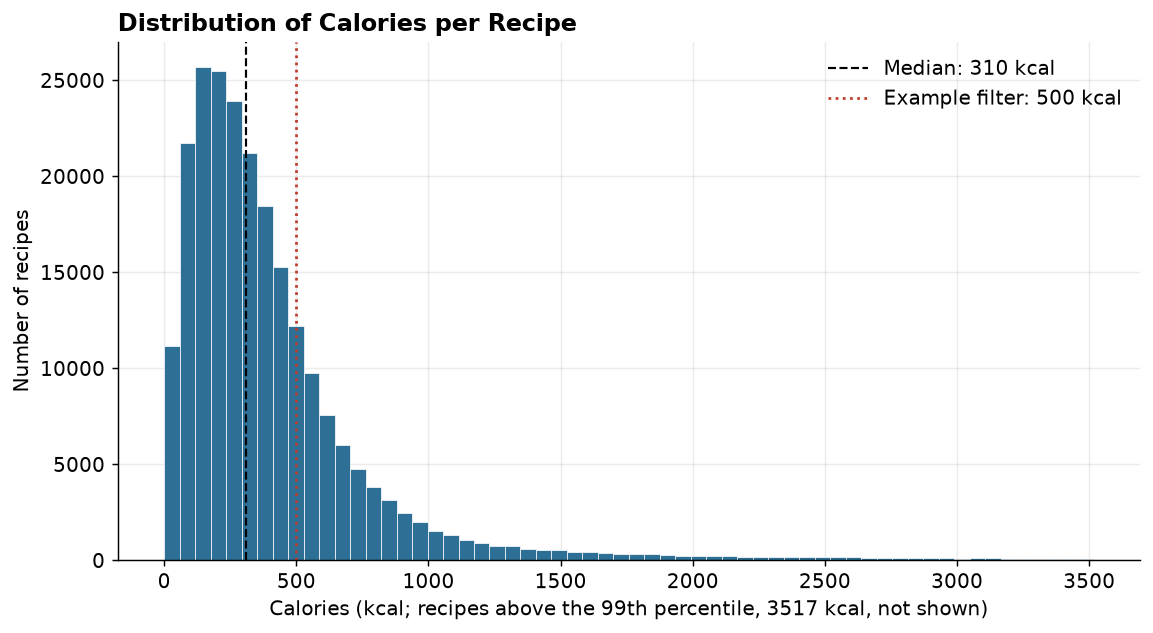

rating
0     5.4
1     1.1
2     1.2
3     3.6
4    16.5
5    72.1
Name: count, dtype: float64


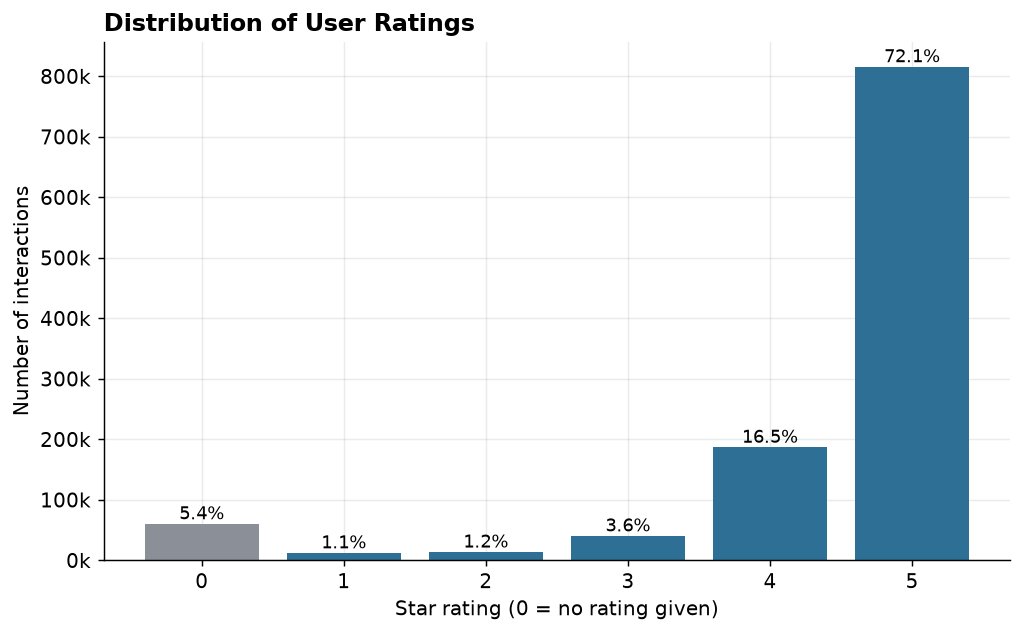

In [5]:
plt.rcParams.update({
    "figure.dpi": 130, "font.family": "sans-serif", "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
})
BLUE, GREY = "#2E6F95", "#8A8F98"

print(recipes["calories"].describe(percentiles=[.05, .25, .5, .75, .95, .99]).round(1))
print("Share of recipes <= 500 kcal: %.1f%%" % ((recipes["calories"] <= 500).mean() * 100))

# --- Figure 1: calorie distribution (clipped at the 99th percentile for readability) ---
cal_cap = recipes["calories"].quantile(0.99)
cal = recipes.loc[recipes["calories"] <= cal_cap, "calories"]

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(cal, bins=60, color=BLUE, edgecolor="white", linewidth=0.4)
ax.axvline(cal.median(), color="black", ls="--", lw=1.2,
           label=f"Median: {cal.median():.0f} kcal")
ax.axvline(500, color="#C0392B", ls=":", lw=1.5, label="Example filter: 500 kcal")
ax.set_title("Distribution of Calories per Recipe", fontweight="bold", loc="left")
ax.set_xlabel(f"Calories (kcal; recipes above the 99th percentile, {cal_cap:.0f} kcal, not shown)")
ax.set_ylabel("Number of recipes")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("fig_calorie_distribution.png", bbox_inches="tight")
plt.show()

# --- Figure 2: rating distribution (0-5) ---
rating_counts = interactions["rating"].value_counts().sort_index()
rating_share = rating_counts / rating_counts.sum() * 100
print(rating_share.round(1))

fig, ax = plt.subplots(figsize=(8, 5))
colors = [GREY if r == 0 else BLUE for r in rating_counts.index]
bars = ax.bar(rating_counts.index.astype(str), rating_counts.values, color=colors)
for bar, pct in zip(bars, rating_share):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f"{pct:.1f}%", ha="center", va="bottom", fontsize=10)
ax.set_title("Distribution of User Ratings", fontweight="bold", loc="left")
ax.set_xlabel("Star rating (0 = no rating given)")
ax.set_ylabel("Number of interactions")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))
plt.tight_layout()
plt.savefig("fig_rating_distribution.png", bbox_inches="tight")
plt.show()

## Step 5: NLP insight, a pre-cursor to the substitution network

In [6]:
pattern = r"\b(?:instead of|substituted|substituting|in place of|replaced)\b"

mask = interactions["review"].str.contains(pattern, case=False, regex=True)
print(f"Reviews mentioning a substitution cue: {mask.sum():,} "
      f"({mask.mean() * 100:.1f}% of all reviews)")

# Pick a readable, positive example: 5 stars, moderate length
candidates = interactions[mask & (interactions["rating"] == 5)
                          & interactions["review"].str.len().between(80, 300)]
example = candidates.sample(3, random_state=42)

for _, row in example.iterrows():
    recipe_name = recipes.loc[recipes["id"] == row["recipe_id"], "name"]
    print(f"\nRecipe : {recipe_name.iloc[0] if len(recipe_name) else 'n/a'}")
    print(f"Rating : {row['rating']}")
    print(f"Review : {row['review']}")

Reviews mentioning a substitution cue: 117,373 (10.4% of all reviews)



Recipe : ravioli in mushroom cream sauce
Rating : 5
Review : I didn't have diced tomatos but I did have salsa. I used left over noodles instead of ravioli and it still was awesome.

Recipe : deviled eggs with fresh tarragon and capers
Rating : 5
Review : Very good.  The olive oil added an interesting and delicious dimension to traditional deviled eggs!  The only thing I didn't have was celery so I left it out.  Used dried tarragon instead of fresh.  Yum!

Recipe : bacon wrapped jalapeno peppers
Rating : 5
Review : I make a similar version, but I mix half cream cheese and half cheddar; cut the jalapenos in half and wrap each filled half in bacon, and bake instead of fry.

These are really delicious, either way!


## Step 6: Ingredient frequency analysis (the node vocabulary of the substitution graph)

Distinct ingredient strings: 14942
Total ingredient mentions  : 2096572
Mean ingredients per recipe: 9.1
Ingredients used in exactly 1 recipe : 3546 (23.7%)
Ingredients used in <= 10 recipes    : 9201 (61.6%)
Ingredients used in >= 1,000 recipes : 316 (2.1%)
Share of all mentions covered by the 100 most frequent ingredients: 51.9%

Top 20 ingredients:


,recipes
ingredient,
salt,85746
butter,54975
sugar,44535
onion,39065
water,34914
eggs,33761
olive oil,32821
flour,26266
milk,25786


Examples of ingredients appearing in only one recipe:
['15 inch pizza crusts', 'fresh pimiento peppers', 'unsweetened strawberry preserves', 'hot and spicy shake-and-bake', 'orgran no egg', 'chocolate truffles', 'hatch chile', 'hershey nuggets chocolate candy bars with almonds', 'camomile tea bags', 'cranberry-strawberry drink', 'bushmills whiskey', 'nestl toll house ultimates refrigerated chocolate chip lovers cookie dough', 'plastic sandwich bag', 'frozen tempura shrimp', 'gummy fruit slices']


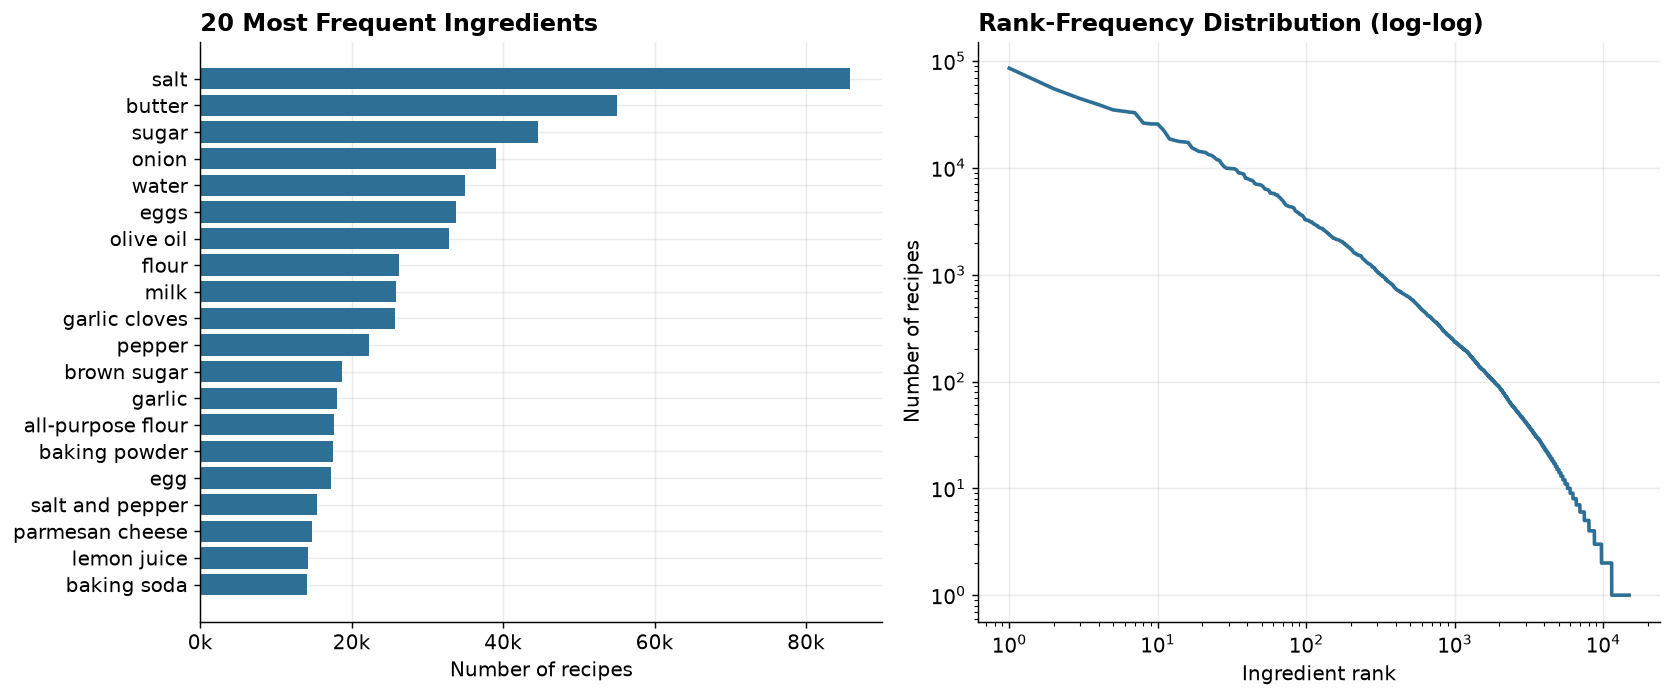

Profile of the 15 most frequent ingredients:


,recipes,mean_calories,mean_rating,review_mentions
ingredient,,,,
salt,85746,508.77,4.57,49511
butter,54975,583.35,4.59,62854
sugar,44535,611.88,4.57,74446
onion,39065,446.94,4.55,42576
water,34914,525.60,4.54,40620
eggs,33761,677.58,4.56,17770
olive oil,32821,441.89,4.60,16555
flour,26266,637.13,4.53,36766
milk,25786,554.64,4.53,42313


Profile of 15 randomly chosen rare ingredients (5-20 recipes):


,recipes,mean_calories,mean_rating,review_mentions
ingredient,,,,
boneless salmon fillets,16,574.63,4.60,0
coffee ice cubes,13,275.85,4.69,30
conchiglie,9,802.83,4.46,6
peppermint oil,9,565.12,4.70,34
dried peppermint,8,95.04,4.90,1
imitation maple flavor,7,1295.23,4.10,2
lean beef round,7,370.49,4.02,0
bite size shredded whole wheat cereal,7,189.91,4.61,0
head white cabbage,6,703.73,4.08,0


In [7]:
# One row per (recipe, ingredient) pair
ing = recipes[["id", "ingredients", "calories"]].explode("ingredients").rename(columns={"ingredients": "ingredient"})
ing_counts = ing["ingredient"].value_counts()

print("Distinct ingredient strings:", len(ing_counts))
print("Total ingredient mentions  :", int(ing_counts.sum()))
print("Mean ingredients per recipe: %.1f" % recipes["n_ingredients"].mean())
print("Ingredients used in exactly 1 recipe : %d (%.1f%%)" % ((ing_counts == 1).sum(), (ing_counts == 1).mean() * 100))
print("Ingredients used in <= 10 recipes    : %d (%.1f%%)" % ((ing_counts <= 10).sum(), (ing_counts <= 10).mean() * 100))
print("Ingredients used in >= 1,000 recipes : %d (%.1f%%)" % ((ing_counts >= 1000).sum(), (ing_counts >= 1000).mean() * 100))
top100_share = ing_counts.head(100).sum() / ing_counts.sum() * 100
print("Share of all mentions covered by the 100 most frequent ingredients: %.1f%%" % top100_share)

print("\nTop 20 ingredients:")
display(ing_counts.head(20).to_frame("recipes"))
print("Examples of ingredients appearing in only one recipe:")
print(ing_counts[ing_counts == 1].sample(15, random_state=42).index.tolist())

# --- Figure 4: top-20 bar chart and rank-frequency (long-tail) plot ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
top20 = ing_counts.head(20)[::-1]
axes[0].barh(top20.index, top20.values, color=BLUE)
axes[0].set_title("20 Most Frequent Ingredients", fontweight="bold", loc="left")
axes[0].set_xlabel("Number of recipes")
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))

axes[1].loglog(np.arange(1, len(ing_counts) + 1), ing_counts.values, color=BLUE, lw=2)
axes[1].set_title("Rank-Frequency Distribution (log-log)", fontweight="bold", loc="left")
axes[1].set_xlabel("Ingredient rank")
axes[1].set_ylabel("Number of recipes")
plt.tight_layout()
plt.savefig("fig_ingredient_frequency.png", bbox_inches="tight")
plt.show()

# --- Same kind of profile as for swaps: calories, ratings and review mentions of ingredients ---
recipe_rating = (interactions[interactions["rating"] > 0].groupby("recipe_id")["rating"].mean()
                 .rename("mean_rating"))
ing = ing.merge(recipe_rating, left_on="id", right_index=True, how="left")
profile = ing.groupby("ingredient").agg(recipes=("id", "count"),
                                        mean_calories=("calories", "mean"),
                                        mean_rating=("mean_rating", "mean"))

def review_mentions(name):
    return int(interactions["review"].str.contains(rf"\b{re.escape(name)}\b", case=False, regex=True).sum())

top15 = profile.sort_values("recipes", ascending=False).head(15).copy()
top15["review_mentions"] = [review_mentions(n) for n in top15.index]
print("Profile of the 15 most frequent ingredients:")
display(top15.round(2))

# Rare ingredients (used in 5-20 recipes) for contrast: sample of 15
rare = profile[(profile["recipes"] >= 5) & (profile["recipes"] <= 20)].sample(15, random_state=42).copy()
rare["review_mentions"] = [review_mentions(n) for n in rare.index]
print("Profile of 15 randomly chosen rare ingredients (5-20 recipes):")
display(rare.sort_values("recipes", ascending=False).round(2))

### Step 6b: Ingredient frequencies on the canonical vocabulary (ingr_map)

Raw vocabulary (RAW_recipes)       : 14942 distinct strings
Canonical vocabulary (PP_recipes)  : 7993 distinct ingredients
Canonical ingredients in exactly 1 recipe : 271 (3.4%)
Canonical ingredients in <= 10 recipes    : 4032 (50.4%)
Canonical ingredients in >= 1,000 recipes : 265 (3.3%)
Share of mentions covered by the 100 most frequent: 56.4%

Top 20 canonical ingredients:


,recipes
ingredient,
salt,66483
butter,43970
onion,39143
egg,39064
sugar,33884
olive oil,31834
garlic clove,27349
water,25953
milk,22063


15 random canonical ingredients used in only one recipe:
['stevia plu', 'umeboshi plum paste', 'mango peach salsa', 'shanghai noodle', 'green swiss chard', 'pluot', 'garlic non-stick spray', 'dried tepin chily', 'pineapple vodka', 'canola margarine', 'french parfait amour liqueur', 'yellow pattypan squash', 'campari tomato', 'home s taco dinner kit', 'chocolate and mint swirled morsel']


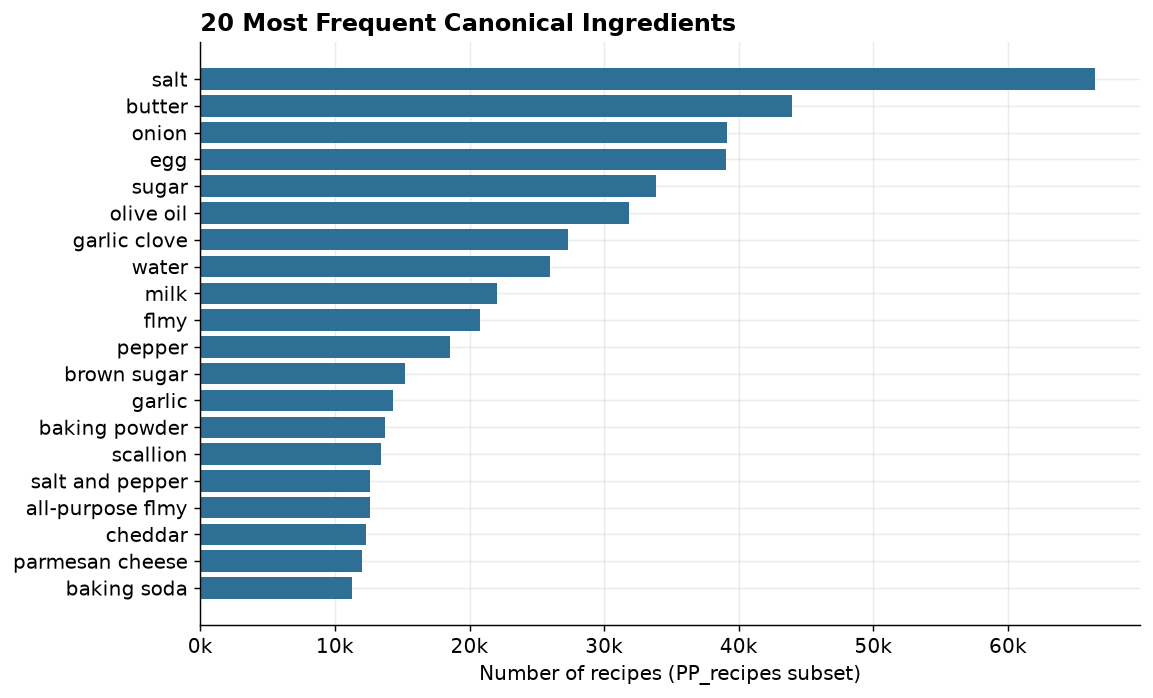

In [8]:
# Canonical ingredient names: ingredient id -> name (one row per canonical id)
id2name = ingr_map.drop_duplicates("id").set_index("id")["replaced"]

pp_ing = pp_recipes[["id", "ingredient_ids"]].copy()
pp_ing["ingredient_ids"] = pp_ing["ingredient_ids"].apply(ast.literal_eval)
pp_ing = pp_ing.explode("ingredient_ids")
pp_ing["ingredient"] = pp_ing["ingredient_ids"].map(id2name)
canon_counts = pp_ing["ingredient"].value_counts()

print("Raw vocabulary (RAW_recipes)       :", len(ing_counts), "distinct strings")
print("Canonical vocabulary (PP_recipes)  :", len(canon_counts), "distinct ingredients")
print("Canonical ingredients in exactly 1 recipe : %d (%.1f%%)" % ((canon_counts == 1).sum(), (canon_counts == 1).mean() * 100))
print("Canonical ingredients in <= 10 recipes    : %d (%.1f%%)" % ((canon_counts <= 10).sum(), (canon_counts <= 10).mean() * 100))
print("Canonical ingredients in >= 1,000 recipes : %d (%.1f%%)" % ((canon_counts >= 1000).sum(), (canon_counts >= 1000).mean() * 100))
print("Share of mentions covered by the 100 most frequent: %.1f%%" % (canon_counts.head(100).sum() / canon_counts.sum() * 100))

print("\nTop 20 canonical ingredients:")
display(canon_counts.head(20).to_frame("recipes"))
print("15 random canonical ingredients used in only one recipe:")
print(canon_counts[canon_counts == 1].sample(15, random_state=42).index.tolist())

fig, ax = plt.subplots(figsize=(9, 5.5))
t = canon_counts.head(20)[::-1]
ax.barh(t.index, t.values, color=BLUE)
ax.set_title("20 Most Frequent Canonical Ingredients", fontweight="bold", loc="left")
ax.set_xlabel("Number of recipes (PP_recipes subset)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))
plt.tight_layout()
plt.savefig("fig_canonical_ingredients.png", bbox_inches="tight")
plt.show()

## Extra: targeted health-oriented substitutions (frequency and success of known swaps)

Corpus mean rating (rated only): 4.66


,swap,reviews,mean_rating,share_4plus_%
0,sugar -> splenda/stevia,2489,4.80,98.20
1,heavy cream -> milk,912,4.74,97.59
2,butter -> olive oil,762,4.77,97.94
3,oil -> applesauce,717,4.66,95.19
4,sour cream -> yogurt,710,4.74,96.38
5,sugar -> honey,550,4.76,97.06
6,butter -> applesauce,218,4.76,98.55
7,white flour -> whole wheat,167,4.70,95.68
8,ground beef -> ground turkey,126,4.73,97.52
9,mayonnaise -> yogurt,101,4.73,98.97


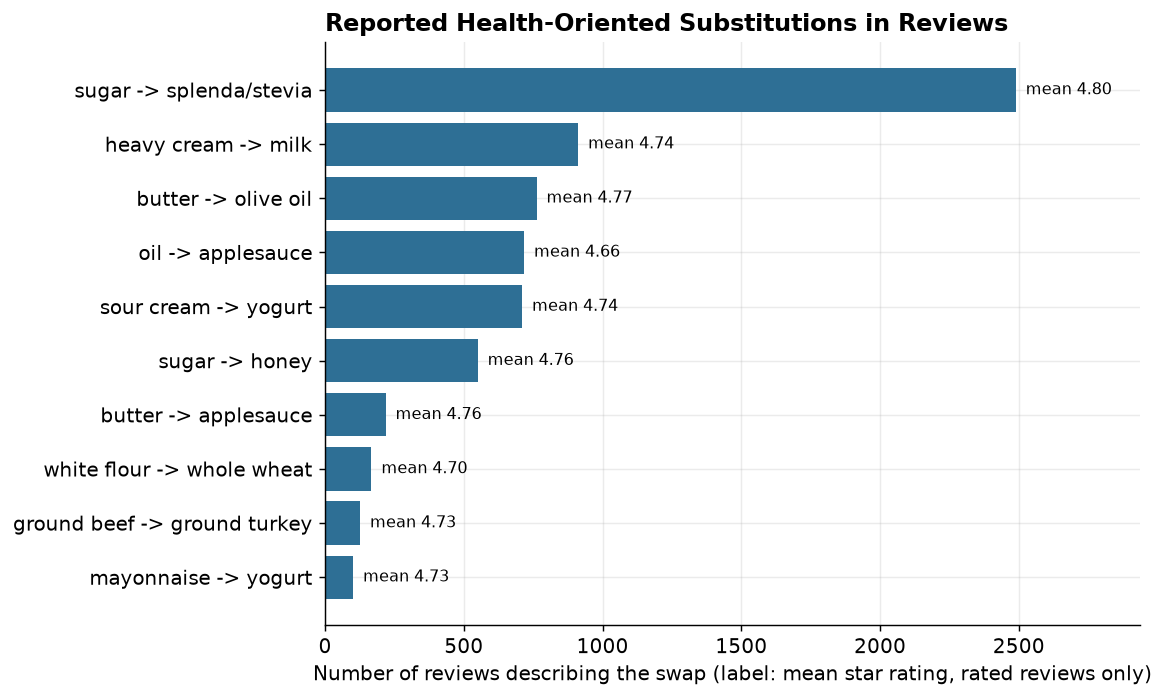


[sugar -> splenda/stevia] grandparent mocktails  1 and  2  non alcoholic  (421 kcal, 7% PDV fat)
Review : I made the 'Orange You Glad' drink because we love Orange Juliuses (and this one is no exception)! I used Splenda for the sugar. This is a great refreshing 'anytime' beverage. Thanks for posting this wonderful treat!



[heavy cream -> milk] chicken in creamy yoghurt sauce  (500 kcal, 41% PDV fat)
Review : I love everything about this chicken in yogurt sauce. It's so creamy and flavorful. It made a beautiful dinner for us tonight. I halved the recipe, and subbed evaporated milk for the cream, but didn't make any other changes. It's wonderful. Thank you very much for posting it.



[butter -> olive oil] broccoli blue cheese fettuccine  (836 kcal, 81% PDV fat)
Review : This is decadently good.  I add crushed red pepper to the oil while sauteing and substitute half-and-half for the heavy cream and olive oil for the butter.


In [9]:
# Each swap: (replaced ingredient, replacing ingredient) with regexes for the review text
swaps = {
    "butter -> applesauce":        (r"butter",              r"(?:unsweetened\s+)?applesauce"),
    "oil -> applesauce":           (r"(?:vegetable\s+|canola\s+)?oil", r"(?:unsweetened\s+)?applesauce"),
    "butter -> olive oil":         (r"butter",              r"olive\s+oil"),
    "sugar -> honey":              (r"(?:white\s+|granulated\s+)?sugar", r"honey"),
    "sugar -> splenda/stevia":     (r"(?:white\s+|granulated\s+)?sugar", r"(?:splenda|stevia|sweetener)"),
    "sour cream -> yogurt":        (r"sour\s+cream",        r"(?:greek\s+|plain\s+)?yogh?urt"),
    "mayonnaise -> yogurt":        (r"mayo(?:nnaise)?",     r"(?:greek\s+|plain\s+)?yogh?urt"),
    "heavy cream -> milk":         (r"(?:heavy\s+|whipping\s+)?cream", r"(?:skim\s+|low[- ]fat\s+)?milk"),
    "white flour -> whole wheat":  (r"(?:white\s+|all[- ]purpose\s+)?flour", r"whole\s+wheat\s+flour"),
    "ground beef -> ground turkey":(r"ground\s+beef",       r"ground\s+turkey"),
}
gap = r"(?:\w+\s+){0,2}"   # allows up to two filler words, e.g. "the", "half of the"

def swap_pattern(old, new):
    # "<new> instead of / in place of / for <old>"  |  "replaced/substituted <old> with <new>"
    # |  "substituted <new> for <old>"
    return (rf"\b{new}\s+(?:instead\s+of|in\s+place\s+of|for)\s+{gap}{old}\b"
            rf"|\b(?:replaced|substituted|subbed|swapped)\s+{gap}{old}\s+(?:with|for|by)\s+{gap}{new}\b"
            rf"|\b(?:substituted|subbed|substitute)\s+{new}\s+for\s+{gap}{old}\b")

rated = interactions["rating"] > 0
rows, masks = [], {}
for label, (old, new) in swaps.items():
    m = interactions["review"].str.contains(swap_pattern(old, new), case=False, regex=True)
    masks[label] = m
    sub = interactions[m]
    rows.append({
        "swap": label,
        "reviews": int(m.sum()),
        "mean_rating": sub.loc[sub["rating"] > 0, "rating"].mean(),
        "share_4plus_%": (sub.loc[sub["rating"] > 0, "rating"] >= 4).mean() * 100,
    })

swap_df = pd.DataFrame(rows).sort_values("reviews", ascending=False).reset_index(drop=True)
corpus_mean = interactions.loc[rated, "rating"].mean()
print(f"Corpus mean rating (rated only): {corpus_mean:.2f}")
display(swap_df.round(2))

# --- Figure 3: how often each swap is reported, coloured by success ---
fig, ax = plt.subplots(figsize=(9, 5.5))
plot_df = swap_df.iloc[::-1]
bars = ax.barh(plot_df["swap"], plot_df["reviews"], color=BLUE)
for bar, mr in zip(bars, plot_df["mean_rating"]):
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2,
            f"  mean {mr:.2f}", va="center", fontsize=9)
ax.set_title("Reported Health-Oriented Substitutions in Reviews", fontweight="bold", loc="left")
ax.set_xlabel("Number of reviews describing the swap (label: mean star rating, rated reviews only)")
ax.set_xlim(0, plot_df["reviews"].max() * 1.18)
plt.tight_layout()
plt.savefig("fig_health_swaps.png", bbox_inches="tight")
plt.show()

# --- Example reviews for the three most frequent swaps, linked to the recipe's nutrition ---
for label in swap_df["swap"].head(3):
    cand = interactions[masks[label] & (interactions["rating"] == 5)
                        & interactions["review"].str.len().between(80, 300)]
    row = cand.sample(1, random_state=1).iloc[0]
    rec = recipes.loc[recipes["id"] == row["recipe_id"]].iloc[0]
    print(f"\n[{label}] {rec['name']}  ({rec['calories']:.0f} kcal, {rec['total_fat_pdv']:.0f}% PDV fat)")
    print("Review :", row["review"])